# Task 1: Verified recursive self-training (Amharic news topic classification)
Loop: generate pseudo-labels -> verify (confidence + independent char-n-gram model) -> retrain a copy -> accept/rollback on **dev** -> repeat. Gold labels of the pool are used only to *measure* pseudo-label precision. The test split is used only in the final cell.

In [1]:
import sys, pathlib
ROOT = pathlib.Path.cwd()
while not (ROOT / "configs").exists() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from src.utils import load_config
from src.data import load_base, make_split
from src.features import attach_views

DATA_SOURCE = "local"   # "local" (data/raw TSVs), "hf", or "synthetic" (smoke test only)
cfg = load_config(overrides={"data.source": DATA_SOURCE})
base = attach_views(load_base(cfg), cfg)
cfg["_n_classes"] = base.n_classes
print(base.label_names, {k: len(v) for k, v in base.texts.items()})

['business', 'health', 'politics', 'sports'] {'train': 1311, 'dev': 188, 'test': 376}


In [2]:
from task1_recursive.selftrain import run_selftrain
SEED = 0
split = make_split(base, SEED, cfg['data']['seed_per_class'])
print('seed set:', len(split.seed_idx), 'pool:', len(split.pool_idx))
res = run_selftrain(base, split, cfg, SEED)
hist = pd.DataFrame(res.history)
hist

seed set: 80 pool: 1231
  [seed 0] round 0 baseline dev macro-F1=0.7892
  [seed 0] round 1: cand=20 precision=1.000 dev F1 0.7962 -> accepted (current 0.7962)
  [seed 0] round 2: cand=36 precision=1.000 dev F1 0.8092 -> accepted (current 0.8092)
  [seed 0] round 3: cand=61 precision=0.984 dev F1 0.7392 -> rejected (current 0.8092)
  [seed 0] round 4: cand=61 precision=0.984 dev F1 0.7293 -> rejected (current 0.8092)
  [seed 0] stopping: 2 consecutive rejections


,round,decision,pool_remaining,n_candidates,n_accepted_total,pl_precision,dev_macro_f1,dev_ece,class_entropy
0,0,baseline,1231,0,0,NaN,0.789187,0.278513,NaN
1,1,accepted,1231,20,20,1.000000,0.796231,0.256904,0.845113
2,2,accepted,1211,36,56,1.000000,0.809165,0.231300,0.555251
3,3,rejected,1175,61,56,0.983607,0.739197,0.131528,0.446974
4,4,rejected,1175,61,56,0.983607,0.729282,0.133987,0.446974


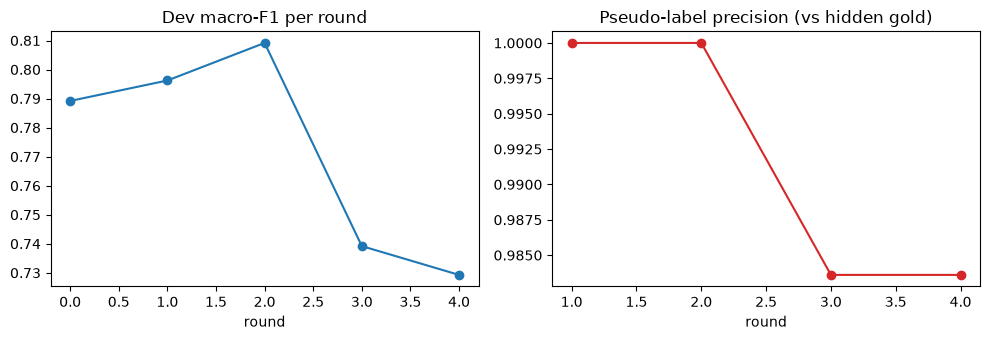

In [3]:
fig, ax = plt.subplots(1, 2, figsize=(10, 3.5))
ax[0].plot(hist['round'], hist['dev_macro_f1'], marker='o'); ax[0].set_title('Dev macro-F1 per round'); ax[0].set_xlabel('round')
ax[1].plot(hist['round'], hist['pl_precision'], marker='o', color='tab:red'); ax[1].set_title('Pseudo-label precision (vs hidden gold)'); ax[1].set_xlabel('round')
plt.tight_layout(); plt.show()

In [5]:
from src.eval import scores
Xt = base.X['teacher']; y = base.y['test']
for name, m in [('round-0 teacher', res.teacher_round0), ('final teacher', res.teacher_final)]:
    print(name, {k: round(v, 4) for k, v in scores(m.proba(Xt['test']), y).items()})

round-0 teacher {'macro_f1': 0.8435, 'accuracy': 0.8457, 'ece': 0.3109}
final teacher {'macro_f1': 0.8456, 'accuracy': 0.8484, 'ece': 0.2474}


Full multi-seed comparison (verified vs confidence-only vs naive): `python -m task1_recursive.run`.